# MoE routing during natural illumination changes

Evaluate the **existing three-epoch MoE-MAE checkpoint** on two visually verified BDD tunnel-exit videos. Each test is one original driving sequence with its own timestamps: no unrelated clips are joined, reversed, darkened, or used for further training.

The clips show **tunnel → daylight**, not a literal sunset. Camera auto-exposure, color temperature, motion, and scene content also change, so routing changes cannot be attributed to illumination alone. Full-frame sRGB luma is an exposure proxy, not a physical light measurement. Videos were selected for visible transitions; this is an exploratory case study.

Run this notebook independently of the training notebook. It loads the trained checkpoint without optimizer updates. The original training notebook and its saved outputs remain unchanged.

```powershell
uv run --extra cpu --with pandas --with matplotlib --with opencv-python-headless --with jupyterlab jupyter lab
```

Use the project's CUDA extra/kernel to accelerate evaluation if available.


In [2]:
import json
import math
import re
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir()), None)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from inside the cafl4ds repository.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [3]:
from collections.abc import Iterator

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display as show
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF

from cafl4ds.jsonio import dumps_valid
from cafl4ds.models.vit import MoEViTEncoder, patchify, unpatchify
from cafl4ds.ssl.factory import build_mae

## Dataset and train/support/test split — edit here

All split settings and construction code live in this notebook. Set `bdd_root` to your extracted BDD
directory if automatic local discovery does not find it. The notebook reads images and original BDD
attributes directly; it does not import train/test membership from a previous notebook.

- `split_mode="official"` keeps the full official training split and divides official validation
  clips using **support_fraction:test_fraction**. `train_fraction` is unused in this mode.
- `split_mode="random"` combines official train/val and assigns clips using **train_fraction,
  support_fraction, test_fraction**, which must be positive and sum to 1. For example, 0.8/0.1/0.1.
- Support images fit the linear/kNN readouts; test (`query`) images measure performance.
- Set both evaluation caps to `None` to use the full allocated support/test panels. Fractions apply
  before label filtering, sparse-stratum rounding and caps; actual counts are printed and saved.
- Splits are seeded, stratified and disjoint by **clip ID**. Known video clips are excluded first.
  Training seeds and model arms share the same split when these settings match.

Use a fresh run when changing the split. A warm-start/frozen checkpoint must have trained on disjoint
clips; those notebooks check this explicitly. Saved plots below describe their original completed
runs until you rerun the affected cells with the edited settings.


In [ ]:
# Edit the dataset and split here; no pre-generated CSVs or external configuration are needed.
bdd_root = None  # Set a local path here if automatic dataset discovery cannot find your BDD extraction.
split_mode = "official"  # "official": keep BDD train/val; "random": split the combined image pool.
train_fraction = 0.80  # Used by random mode; official mode retains all official training images.
support_fraction = 0.10  # Labeled support fits the frozen linear/kNN readouts.
test_fraction = 0.10  # Held-out test images are called query in the existing evaluation code.
split_seed = 13  # Use the same value in each notebook for paired comparisons.
split_stratify_by = ("scene", "regime")  # Add "weather", or use () for unstratified splitting.
support_per_scene = 32  # Optional cap AFTER splitting; None uses every eligible support image.
query_per_scene_regime = 64  # Optional cap AFTER splitting; None uses every eligible test image.
extra_excluded_clip_ids = []  # Additional video/sequence IDs to reserve from all still-image partitions.
video_exclusion_manifests = [
    "outputs/bdd-illumination/selected_videos.json",
    "outputs/bdd-day-dusk-night/matched_sources.json",
    "outputs/bdd-video-subset/video_manifest.json",
]

In [ ]:
# Split construction is embedded here; this notebook does not import an external split/config script.
import csv as split_csv
import hashlib as split_hashlib
import json as split_json
import math as split_math
from collections import defaultdict as split_defaultdict


def valid_bdd_root(path: Path) -> bool:
    """Recognize the extracted BDD still-image layout without requiring a previous experiment."""
    return all((path / "images/100k" / name).is_dir() for name in ["train", "val"])


def resolve_bdd_root(configured: str | Path | None) -> Path:
    """Use the notebook's path or discover a local dataset; saved CSVs supply path hints only."""
    if configured is not None:
        candidate = Path(configured).expanduser()
        candidate = candidate if candidate.is_absolute() else repo_root / candidate
        if not valid_bdd_root(candidate):
            raise FileNotFoundError(f"Expected images/100k/train and val below bdd_root={candidate}.")
        return candidate.resolve()
    candidates = [repo_root / name for name in ["data/bdd100k", "data", "bdd100k", "datasets/bdd100k"]]
    for family in ["moe-stills-to-video", "moe-router-comparison", "moe-router-illumination-comparison"]:
        for filename in ["ssl_train.csv", "train.csv"]:
            for manifest in sorted((repo_root / "outputs" / family).glob(f"*/{filename}"), reverse=True):
                with manifest.open(newline="", encoding="utf-8") as stream:
                    first = next(split_csv.DictReader(stream), None)
                if first and first.get("path"):
                    candidates.extend(Path(first["path"]).parents)
    for candidate in candidates:
        if valid_bdd_root(candidate):
            return candidate.resolve()
    raise FileNotFoundError("Set bdd_root in this notebook to your extracted BDD image/label directory.")


def read_bdd_attributes(folder: Path, split: str) -> dict:
    """Read combined or per-image official attributes directly from the configured dataset."""
    combined = folder / "labels" / f"bdd100k_labels_images_{split}.json"
    individual = folder / "labels/100k" / split
    if combined.is_file():
        items = split_json.loads(combined.read_text(encoding="utf-8"))
    elif individual.is_dir():
        items = [split_json.loads(p.read_text(encoding="utf-8")) for p in sorted(individual.glob("*.json"))]
    else:
        raise FileNotFoundError(f"Missing BDD attributes: {combined} or {individual}")
    return {Path(item["name"]).stem: item.get("attributes", {}) for item in items}


def read_bdd_stills(folder: Path) -> list[dict]:
    """Read paths and attributes, without decoding images or loading a saved split."""
    rows = []
    for split in ["train", "val"]:
        attributes = read_bdd_attributes(folder, split)
        for path in sorted((folder / "images/100k" / split).iterdir()):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            attrs = attributes.get(path.stem, {})
            rows.append(
                {
                    "path": str(path),
                    "clip_id": path.stem,
                    "split": split,
                    "scene": attrs.get("scene") or "undefined",
                    "regime": attrs.get("timeofday") or "unknown",
                    "weather": attrs.get("weather") or "undefined",
                }
            )
    return rows


def reserved_video_ids() -> set[str]:
    """Exclude every configured evaluation-video clip before assigning still-image partitions."""
    result = set(extra_excluded_clip_ids)
    for relative in video_exclusion_manifests:
        path = repo_root / relative
        if path.is_file():
            entries = split_json.loads(path.read_text(encoding="utf-8"))
            result.update(str(row["clip_id"]) for row in entries)
    return result


def split_counts(size: int, fractions: list[float]) -> list[int]:
    """Use largest-remainder rounding; retain each partition in sufficiently large strata."""
    expected = [size * fraction for fraction in fractions]
    counts = [split_math.floor(value) for value in expected]
    order = sorted(range(len(counts)), key=lambda i: (expected[i] - counts[i], fractions[i]), reverse=True)
    for index in order[: size - sum(counts)]:
        counts[index] += 1
    if size >= len(counts):
        for index, count in enumerate(counts):
            if count == 0:
                donor = max(range(len(counts)), key=lambda i: counts[i] - expected[i])
                if counts[donor] <= 1:
                    donor = max(range(len(counts)), key=lambda i: counts[i])
                counts[donor] -= 1
                counts[index] += 1
    return counts


def partition_clips(rows: list[dict], names: list[str], fractions: list[float]) -> dict:
    """Assign entire clips using stable seeded ordering within the requested metadata strata."""
    clips = split_defaultdict(list)
    for row in rows:
        clips[str(row["clip_id"])].append(row)
    strata = split_defaultdict(list)
    for clip_id, members in clips.items():
        keys = {tuple(str(row.get(key, "unknown")) for key in split_stratify_by) for row in members}
        if len(keys) != 1:
            raise ValueError(f"Conflicting stratification attributes within clip {clip_id}.")
        strata[next(iter(keys))].append(clip_id)
    partitions = {name: [] for name in names}
    for key in sorted(strata):
        ordered = sorted(
            strata[key], key=lambda clip: split_hashlib.sha256(f"{split_seed}|{clip}".encode()).hexdigest()
        )
        counts = split_counts(len(ordered), fractions)
        start = 0
        for name, count in zip(names, counts, strict=True):
            partitions[name].extend(row for clip in ordered[start : start + count] for row in clips[clip])
            start += count
    return partitions


def cap_split_groups(rows: list[dict], keys: tuple[str, ...], cap: int | None) -> list[dict]:
    """Apply optional per-group evaluation caps after splitting, retaining whole clips."""
    if cap is None:
        return rows
    if not isinstance(cap, int) or isinstance(cap, bool) or cap < 1:
        raise ValueError("Evaluation caps must be positive integers or None.")
    groups = split_defaultdict(dict)
    for row in rows:
        key = tuple(row[name] for name in keys)
        groups[key].setdefault(row["clip_id"], []).append(row)
    return [row for key in sorted(groups) for members in list(groups[key].values())[:cap] for row in members]


def validate_split_settings() -> list[float]:
    """Validate fractions and stratification before reading any dataset metadata."""
    fractions = [train_fraction, support_fraction, test_fraction]
    if any(not split_math.isfinite(value) or value <= 0 for value in fractions):
        raise ValueError("train_fraction, support_fraction and test_fraction must be finite and positive.")
    if not split_math.isclose(sum(fractions), 1.0, abs_tol=1e-9):
        raise ValueError("train_fraction + support_fraction + test_fraction must equal 1.")
    if split_mode not in {"official", "random"}:
        raise ValueError('split_mode must be "official" or "random".')
    if not set(split_stratify_by).issubset({"scene", "regime", "weather"}):
        raise ValueError("Stratification may use scene, regime, and/or weather; () gives unstratified splitting.")
    return fractions


def build_notebook_splits(extra_video_ids: set[str] | None = None) -> tuple[dict, list[str], dict]:
    """Build train/support/test directly from BDD metadata using only this notebook's settings."""
    fractions = validate_split_settings()
    excluded = reserved_video_ids() | set(extra_video_ids or ())
    all_rows = read_bdd_stills(dataset_root)
    rows = [row for row in all_rows if row["clip_id"] not in excluded]
    if split_mode == "official":
        train = [row for row in rows if row["split"] == "train"]
        evaluation = [row for row in rows if row["split"] == "val"]
        ratio = support_fraction / (support_fraction + test_fraction)
        parts = {"train": train, **partition_clips(evaluation, ["support", "query"], [ratio, 1 - ratio])}
    else:
        parts = partition_clips(rows, ["train", "support", "query"], fractions)
    for name in ["support", "query"]:
        parts[name] = [
            row
            for row in parts[name]
            if row["scene"] not in {"undefined", ""} and row["regime"] in {"daytime", "dawn/dusk", "night"}
        ]
    parts["support"] = cap_split_groups(parts["support"], ("scene",), support_per_scene)
    parts["query"] = cap_split_groups(parts["query"], ("scene", "regime"), query_per_scene_regime)
    scenes = sorted({row["scene"] for row in parts["support"]} & {row["scene"] for row in parts["query"]})
    for name in ["support", "query"]:
        parts[name] = [row for row in parts[name] if row["scene"] in scenes]
    if any(not part for part in parts.values()) or len(scenes) < 2:
        raise ValueError("Split is empty or has fewer than two shared scene classes; increase data/fractions or caps.")
    ids = {name: {row["clip_id"] for row in part} for name, part in parts.items()}
    if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
        raise ValueError("Clip overlap between train/support/test; check duplicate BDD source identifiers.")
    contract = {
        "version": "notebook-bdd-clip-split-v1",
        "dataset_root": str(dataset_root),
        "mode": split_mode,
        "train_fraction": train_fraction,
        "support_fraction": support_fraction,
        "test_fraction": test_fraction,
        "seed": split_seed,
        "stratify_by": list(split_stratify_by),
        "support_per_scene": support_per_scene,
        "query_per_scene_regime": query_per_scene_regime,
        "excluded_video_ids_sha256": split_hashlib.sha256("\n".join(sorted(excluded)).encode()).hexdigest(),
    }
    print("Split built in this notebook:", {name: len(part) for name, part in parts.items()})
    if split_mode == "official":
        print(
            "Official train retained; official val divided by support_fraction:test_fraction; train_fraction is unused."
        )
    print("Fractions apply before unknown-label filtering, sparse-stratum rounding and evaluation caps.")
    return parts, scenes, contract


def guard_notebook_split(folder: Path, contract: dict) -> None:
    """Reject edited split settings before overwriting manifests in an existing run."""
    path = folder / "split_settings.json"
    if path.exists() and split_json.loads(path.read_text()) != contract:
        raise ValueError("Split settings changed. Choose a fresh run directory before regenerating its partitions.")
    path.write_text(split_json.dumps(contract, indent=2), encoding="utf-8")


def find_stills_checkpoint(configured: str | Path | None) -> Path:
    """Find an existing model for notebooks that explicitly perform warm-start or frozen evaluation."""
    candidates = (
        [Path(configured).expanduser()]
        if configured
        else sorted((repo_root / "outputs/moe-stills-to-video").glob("*/checkpoint.pt"), reverse=True)
    )
    for candidate in candidates:
        resolved = candidate if candidate.is_absolute() else repo_root / candidate
        folder = resolved.parent if resolved.is_file() else resolved
        if all((folder / name).is_file() for name in ["checkpoint.pt", "config.json", "ssl_train.csv"]):
            return folder.resolve()
    raise FileNotFoundError("Set checkpoint_run_dir in this notebook to a trained stills-to-video model run.")


def check_pretrained_split(folder: Path, parts: dict) -> None:
    """A warm-start/frozen checkpoint must never have pretrained on the new evaluation clips."""
    with (folder / "ssl_train.csv").open(newline="", encoding="utf-8") as stream:
        trained = {row["clip_id"] for row in split_csv.DictReader(stream)}
    overlap = trained & {row["clip_id"] for name in ["support", "query"] for row in parts[name]}
    overlap |= trained & reserved_video_ids()
    if overlap:
        raise ValueError(
            f"The selected checkpoint trained on {len(overlap)} new support/test clips. "
            "Train moe_stills_to_video with these same split settings first, then select that checkpoint_run_dir."
        )


dataset_root = resolve_bdd_root(bdd_root)

In [ ]:
checkpoint_run_dir = None  # Optional model run path; split settings remain entirely above.
source_run = find_stills_checkpoint(checkpoint_run_dir)
selection_file = repo_root / "outputs/bdd-illumination/selected_videos.json"
configured_videos = json.loads(selection_file.read_text(encoding="utf-8"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size = 16
sample_every_seconds = 0.25
max_video_samples = None
plot_rolling_seconds = 1.0
seed = 13
run_dir = repo_root / "outputs/bdd-illumination/evaluation" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir.mkdir(parents=True, exist_ok=False)
config = json.loads((source_run / "config.json").read_text(encoding="utf-8"))
checkpoint = torch.load(source_run / "checkpoint.pt", map_location="cpu", weights_only=True)
model_config, mae_config = checkpoint["model_config"], checkpoint["mae_config"]
method = build_mae(MoEViTEncoder(**model_config), **mae_config).to(device)
method.load_state_dict(checkpoint["method"], strict=True)
method.eval().requires_grad_(False)
img_size, patch_size = model_config["img_size"], model_config["patch_size"]
num_experts, top_k, moe_blocks = model_config["num_experts"], model_config["top_k"], tuple(model_config["moe_blocks"])
mask_ratio = mae_config["mask_ratio"]
if mae_config["norm_pix_loss"]:
    raise ValueError("This evaluation expects the RGB-target checkpoint (norm_pix_loss=False).")
fixed_mask_noise = torch.load(source_run / "reconstruction_masks.pt", map_location="cpu", weights_only=True)
scene_names = config["probe_scenes"]
scene_to_id = {name: index for index, name in enumerate(scene_names)}
selected_ids = {spec["clip_id"] for spec in configured_videos}
train_ids = set(pd.read_csv(source_run / "ssl_train.csv")["clip_id"])
if selected_ids & train_ids:
    raise ValueError("A selected video was used for SSL training; choose disjoint validation/test clips.")
split_parts, scene_names, split_contract = build_notebook_splits(selected_ids)
check_pretrained_split(source_run, split_parts)
guard_notebook_split(run_dir, split_contract)
scene_to_id = {name: index for index, name in enumerate(scene_names)}
removed_support = 0  # Reserved video clips were excluded before splitting.
support_records, query_records = split_parts["support"], split_parts["query"]
if len({record["scene"] for record in support_records}) < 2:
    raise ValueError("Too few scene classes remain for frozen readout fitting.")
knn_k = config["knn_k"]
pd.DataFrame(support_records).to_csv(run_dir / "probe_support.csv", index=False)
pd.DataFrame(query_records).to_csv(run_dir / "probe_query.csv", index=False)
(run_dir / "config.json").write_text(
    dumps_valid(
        {
            "source_run": str(source_run),
            "split_settings": split_contract,
            "checkpoint_epoch": checkpoint["epoch"],
            "trained_images_per_epoch": checkpoint["history"][-1]["images"],
            "selected_videos": configured_videos,
            "device": str(device),
            "sample_every_seconds": sample_every_seconds,
            "removed_support_clips": removed_support,
            "mode": "frozen evaluation; no optimizer or training updates",
            "reconstruction_masks": len(fixed_mask_noise),
        }
    ),
    encoding="utf-8",
)
print(f"Loaded epoch {checkpoint['epoch']}; {checkpoint['history'][-1]['images']:,} training images per epoch.")
print(f"Device: {device}; removed {removed_support} selected clip(s) from probe fitting.")
print(f"Outputs: {run_dir}")
show(pd.DataFrame(configured_videos)[["clip_id", "regime", "description"]])

## Frozen scene probes and reconstruction

Linear and kNN readouts are refitted on the original validation support panel **after removing the selected test clips**. Queries are also disjoint from these clips. No test-video labels fit either readout. The table below reports scene accuracy on the remaining held-out stills; it is not directly paired to the training notebook's old table because the support/query panels may have changed.

The videos have changing scene content and no framewise scene annotations, so their scene predictions are shown without claiming framewise classification accuracy. Reconstruction is masked RGB MSE with the training run's three fixed mask templates. Lower MSE is better.


In [5]:
class StillDataset(Dataset):
    """Lazy RGB loading with the exact same spatial preprocessing for stills and video."""

    def __init__(self, records: list[dict[str, Any]]) -> None:
        """Retain only paths and metadata."""
        self.records = records

    def __len__(self) -> int:
        """Count available still images."""
        return len(self.records)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        """Decode one image and return its optional scene ID."""
        record = self.records[index]
        with Image.open(record["path"]) as image:
            tensor = preprocess_rgb(np.array(image.convert("RGB")))
        return tensor, scene_to_id.get(record.get("scene"), -1)


def preprocess_rgb(rgb: np.ndarray) -> torch.Tensor:
    """RGB uint8 → float [0,1], resized with antialiasing to the model's square input."""
    tensor = TF.to_tensor(rgb)
    return TF.resize(tensor, [img_size, img_size], antialias=True)


def make_loader(records: list[dict[str, Any]], shuffle: bool = False, epoch: int = 0) -> DataLoader:
    """Use zero workers for portable Windows/Jupyter behavior and a reproducible epoch shuffle."""
    return DataLoader(
        StillDataset(records),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed + epoch),
        pin_memory=device.type == "cuda",
    )


@torch.no_grad()
def reconstruction_mse(images: torch.Tensor) -> torch.Tensor:
    """Return one masked RGB MSE per image, averaged over fixed mask templates."""
    target = patchify(images, patch_size)
    errors = []
    for noise in fixed_mask_noise:
        result = method.encoder.forward_with_aux(
            images, mask_ratio=mask_ratio, mask_noise=noise[None].expand(len(images), -1).to(device)
        )
        prediction = method.decoder(result.tokens, result.ids_restore)
        patch_error = (prediction - target).square().mean(-1)
        errors.append((patch_error * result.mask).sum(-1) / result.mask.sum(-1).clamp_min(1))
    return torch.stack(errors).mean(0)


@torch.no_grad()
def routing_arrays(images: torch.Tensor) -> dict[int, dict[str, np.ndarray]]:
    """Return clean spatial-token probabilities, dispatch shares, and gate weights."""
    output = {}
    for block, probabilities in method.encoder.routing(images).items():
        spatial = probabilities[:, 1:, :]  # CLS is excluded from spatial-token summaries.
        selected = F.one_hot(spatial.topk(top_k, dim=-1).indices, num_experts).sum(-2)
        output[block] = {
            "probability": spatial.mean(1).cpu().numpy(),
            "dispatch_share": (selected.float().mean(1) / top_k).cpu().numpy(),
            "selected_weight": (spatial * selected).mean(1).cpu().numpy(),
        }
    return output


@torch.no_grad()
def encode_records(records: list[dict[str, Any]]) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Read ordered embeddings, labels, and masked reconstruction errors without updating weights."""
    features, labels, errors = [], [], []
    method.eval()
    for cpu_images, targets in make_loader(records):
        images = cpu_images.to(device)
        features.append(method.encode(images).cpu().numpy())
        labels.append(targets.numpy())
        errors.append(reconstruction_mse(images).cpu().numpy())
    if not features:
        raise ValueError("Empty evaluation partition.")
    return np.concatenate(features), np.concatenate(labels), np.concatenate(errors)


def fit_scene_readouts() -> tuple[Any, Any]:
    """Fit only linear/kNN readouts on validation supports, with fixed hyperparameters."""
    features, labels, _ = encode_records(support_records)
    linear = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=seed))
    knn = KNeighborsClassifier(n_neighbors=min(knn_k, len(labels)), metric="cosine", weights="distance")
    return linear.fit(features, labels), knn.fit(features, labels)


def evaluate_stills(stage: str) -> tuple[list[dict[str, Any]], Any, Any]:
    """Score disjoint query clips by regime with a fresh frozen-encoder readout."""
    linear, knn = fit_scene_readouts()
    features, labels, errors = encode_records(query_records)
    predictions = {"linear": linear.predict(features), "knn": knn.predict(features)}
    query_frame = pd.DataFrame(query_records)
    rows = []
    for regime in ["daytime", "night", "dawn/dusk"]:
        indices = np.flatnonzero(query_frame["regime"].to_numpy() == regime)
        if not len(indices):
            continue
        row = {
            "stage": stage,
            "regime": regime,
            "images": len(indices),
            "masked_rgb_mse": float(errors[indices].mean()),
        }
        for name, prediction in predictions.items():
            row[f"{name}_accuracy"] = accuracy_score(labels[indices], prediction[indices])
            row[f"{name}_macro_f1"] = f1_score(labels[indices], prediction[indices], average="macro", zero_division=0)
        rows.append(row)
    return rows, linear, knn

In [6]:
still_rows, linear_readout, knn_readout = evaluate_stills("trained_checkpoint")
still_metrics = pd.DataFrame(still_rows)
still_metrics.to_csv(run_dir / "still_metrics.csv", index=False)
show(still_metrics)

,stage,regime,images,masked_rgb_mse,linear_accuracy,linear_macro_f1,knn_accuracy,knn_macro_f1
0,trained_checkpoint,daytime,208,0.029675,0.346154,0.220641,0.350962,0.232839
1,trained_checkpoint,night,203,0.009528,0.344828,0.238705,0.354680,0.286897
2,trained_checkpoint,dawn/dusk,194,0.026069,0.335052,0.197532,0.391753,0.294768


In [7]:
def directory_video_frames(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Read numbered extracted frames at their original capture rate."""
    path = Path(spec["path"])
    fps = float(spec.get("fps", 0))
    if not math.isfinite(fps) or fps <= 0:
        raise ValueError(f"{path}: frame directories require a positive source fps.")
    indexed = []
    for frame in path.iterdir():
        if frame.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        match = re.search(r"(\d+)$", frame.stem)
        if match is None:
            raise ValueError(f"Frame filename must end with its original frame index: {frame.name}")
        indexed.append((int(match.group(1)), frame))
    indexed.sort()
    if not indexed or len({i for i, _ in indexed}) != len(indexed):
        raise ValueError(f"Empty frame folder or duplicate numeric indices: {path}")
    for index, frame in indexed:
        seconds = (index - indexed[0][0]) / fps
        with Image.open(frame) as image:
            yield index, seconds, np.array(image.convert("RGB")), fps


def decoded_video_frames(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Decode every video frame in capture order and release the decoder on early exit."""
    path = Path(spec["path"])
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        capture.release()
        raise OSError(f"Cannot open video: {path}")
    try:
        fps = float(capture.get(cv2.CAP_PROP_FPS))
        if not math.isfinite(fps) or fps <= 0:
            raise ValueError(f"Video has no valid source FPS: {path}")
        index, previous_seconds = 0, -1.0
        while True:
            success, bgr = capture.read()
            if not success:
                break
            reported = float(capture.get(cv2.CAP_PROP_POS_MSEC)) / 1000
            seconds = reported if math.isfinite(reported) and reported > previous_seconds else index / fps
            if seconds <= previous_seconds:
                raise ValueError(f"Nonmonotonic timestamps in {path} at frame {index}.")
            previous_seconds = seconds
            yield index, seconds, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), fps
            index += 1
    finally:
        capture.release()


def video_frames(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Sample a continuous reader chronologically, without retaining full video in RAM."""
    reader = directory_video_frames(spec) if Path(spec["path"]).is_dir() else decoded_video_frames(spec)
    next_sample, count = 0.0, 0
    try:
        for index, seconds, rgb, fps in reader:
            if seconds + 1e-9 < next_sample:
                continue
            yield index, seconds, rgb, fps
            count += 1
            next_sample = seconds + sample_every_seconds
            if max_video_samples is not None and count >= max_video_samples:
                break
        if not count:
            raise ValueError(f"No frames decoded from {spec['path']}.")
    finally:
        reader.close()


def frame_scene_labels(spec: dict[str, Any]) -> dict[int, str] | None:
    """Optional exact frame annotations override the weaker clip-wide scene label."""
    if not spec.get("frame_labels_csv"):
        return None
    frame = pd.read_csv(spec["frame_labels_csv"])
    if not {"frame_index", "scene"}.issubset(frame.columns) or frame["frame_index"].duplicated().any():
        raise ValueError("frame_labels_csv requires unique frame_index values and a scene column.")
    return dict(zip(frame["frame_index"].astype(int), frame["scene"], strict=True))


@torch.no_grad()
def evaluate_video(spec: dict[str, Any]) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Run frozen inference; retain one row per sampled frame/block/expert and summary scores."""
    method.eval()
    exact_labels = frame_scene_labels(spec)
    rows, pending = [], []
    label_source = "frame annotations" if exact_labels is not None else spec["label_source"]

    def process(batch: list[tuple[int, float, np.ndarray, float]]) -> None:
        images = torch.stack([preprocess_rgb(item[2]) for item in batch]).to(device)
        features = method.encode(images).cpu().numpy()
        linear_predictions, knn_predictions = linear_readout.predict(features), knn_readout.predict(features)
        errors = reconstruction_mse(images).cpu().numpy()
        routing = routing_arrays(images)
        for i, (frame_index, seconds, _, fps) in enumerate(batch):
            truth = exact_labels.get(frame_index) if exact_labels is not None else spec.get("scene")
            for block, arrays in routing.items():
                dominant = int(arrays["dispatch_share"][i].argmax())
                for expert in range(num_experts):
                    rows.append(
                        {
                            "clip_id": spec["clip_id"],
                            "frame_index": frame_index,
                            "seconds": seconds,
                            "source_fps": fps,
                            "block": block,
                            "expert": expert,
                            "dominant_expert": dominant,
                            **{key: float(values[i, expert]) for key, values in arrays.items()},
                            "brightness": float(images[i].mean().item()),
                            "masked_rgb_mse": float(errors[i]),
                            "scene": truth,
                            "label_source": label_source,
                            "linear_scene": scene_names[int(linear_predictions[i])],
                            "knn_scene": scene_names[int(knn_predictions[i])],
                        }
                    )

    for item in video_frames(spec):
        pending.append(item)
        if len(pending) == batch_size:
            process(pending)
            pending = []
    if pending:
        process(pending)
    frame = pd.DataFrame(rows)
    if frame.empty:
        raise ValueError(f"No video samples: {spec['clip_id']}")
    samples = frame.drop_duplicates("frame_index").sort_values("frame_index")
    labeled = samples.loc[samples["scene"].isin(scene_to_id)]
    summary = {
        "clip_id": spec["clip_id"],
        "frames": len(samples),
        "start_seconds": float(samples["seconds"].min()),
        "end_seconds": float(samples["seconds"].max()),
        "masked_rgb_mse": float(samples["masked_rgb_mse"].mean()),
        "labeled_frames": len(labeled),
        "label_source": label_source,
        "linear_accuracy": float((labeled["linear_scene"] == labeled["scene"]).mean()) if len(labeled) else None,
        "knn_accuracy": float((labeled["knn_scene"] == labeled["scene"]).mean()) if len(labeled) else None,
    }
    return frame, summary

In [8]:
video_results, video_summaries = {}, []
for clip_index, spec in enumerate(configured_videos):
    frame, summary = evaluate_video(spec)
    frame["luma"] = np.nan
    lumas = {}
    for frame_index, _seconds, rgb, _fps in video_frames(spec):
        rgb_small = cv2.resize(rgb, (160, 90)).astype(np.float32) / 255.0
        lumas[frame_index] = float((rgb_small @ np.array([0.2126, 0.7152, 0.0722])).mean())
    frame["luma"] = frame["frame_index"].map(lumas)
    frame["phase"] = "transition / excluded from phase comparison"
    for phase in spec["phases"]:
        in_phase = (frame["seconds"] >= phase["start"]) & (frame["seconds"] < phase["end"])
        frame.loc[in_phase, "phase"] = phase["label"]
    video_results[spec["clip_id"]] = frame
    frame.to_csv(run_dir / f"video_{clip_index:02d}_frames.csv", index=False)
    video_summaries.append(summary)
    print(f"{spec['clip_id']}: {summary['frames']} chronological frames; MSE {summary['masked_rgb_mse']:.5f}")
pd.DataFrame(video_summaries).to_csv(run_dir / "video_summary.csv", index=False)
show(pd.DataFrame(video_summaries)[["clip_id", "frames", "end_seconds", "masked_rgb_mse", "labeled_frames"]])

c2b6d359-e8c54604: 151 chronological frames; MSE 0.02290


b56a0885-1c282ea8: 151 chronological frames; MSE 0.02182


,clip_id,frames,end_seconds,masked_rgb_mse,labeled_frames
0,c2b6d359-e8c54604,151,40.023333,0.022905,0
1,b56a0885-1c282ea8,151,39.861667,0.021819,0


## Routing on the same timeline as the light change

Soft probabilities show router preference. **Hard dispatch shares show which experts actually receive spatial tokens**; with top-1 they sum to 100% of patches. Selected gate weights quantify the unrenormalized expert output scaling used by this repository. CLS is excluded from these spatial summaries. The dominant expert is the largest dispatch share, not necessarily the only expert active in a frame.

Vertical markers are approximate, visually checked tunnel-exit intervals. Shaded phase windows deliberately leave an ambiguous transition gap. No statistical significance is inferred from correlated adjacent frames.


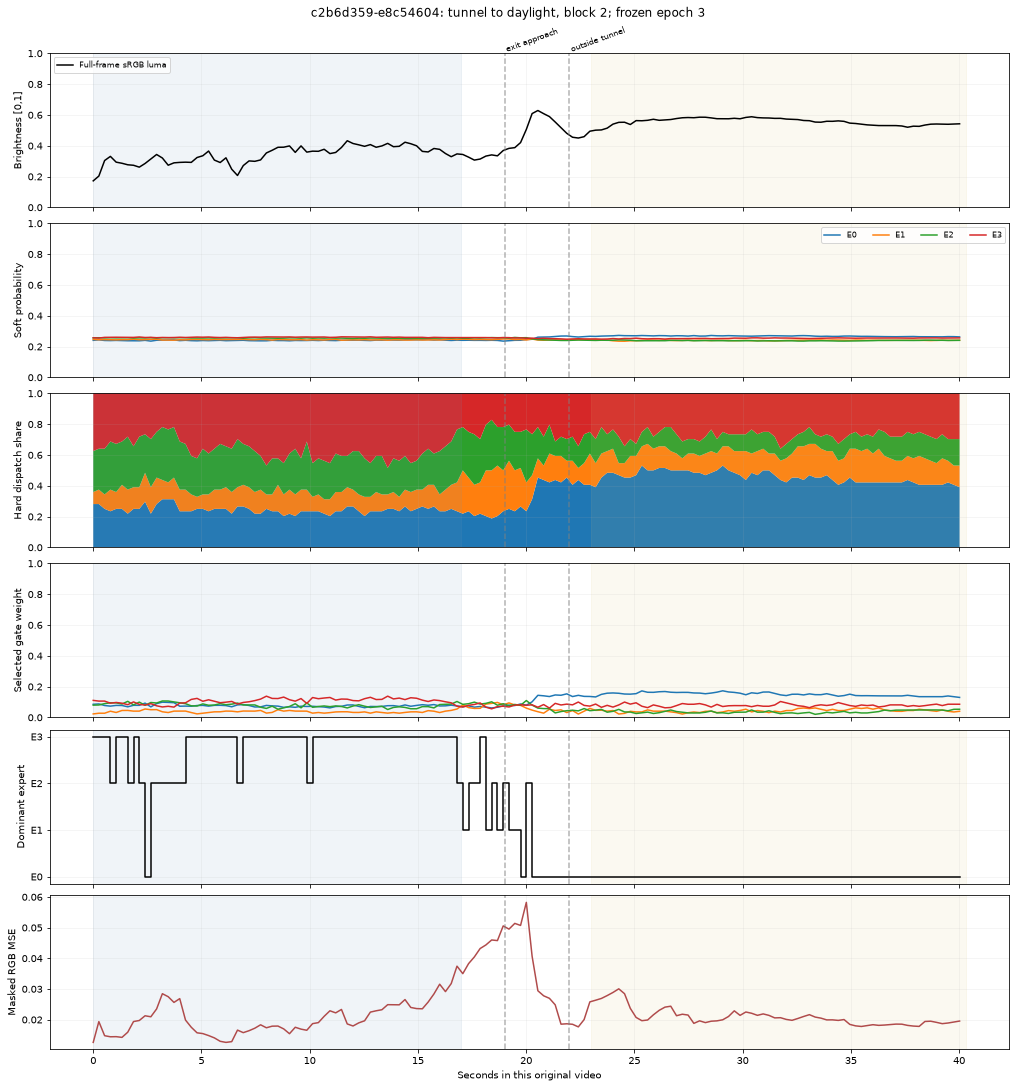

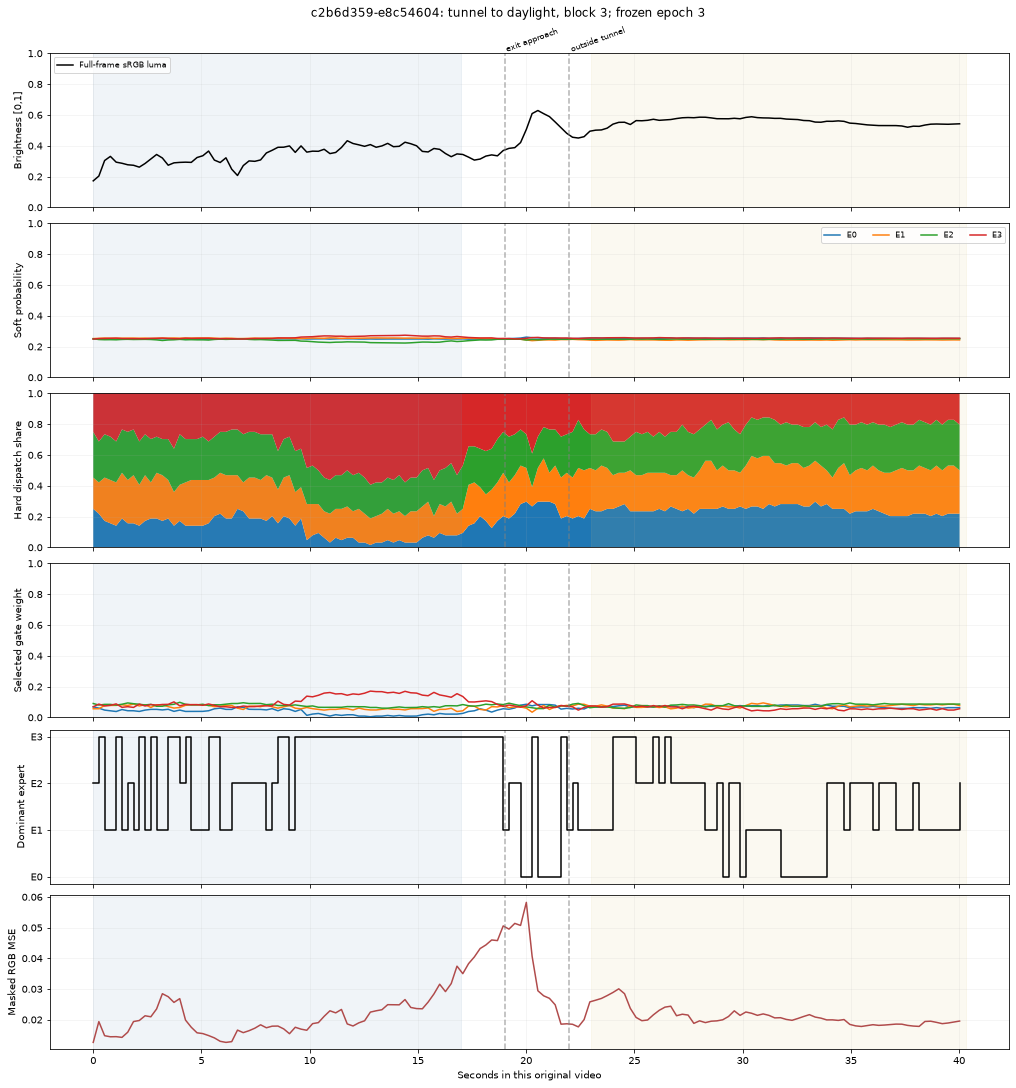

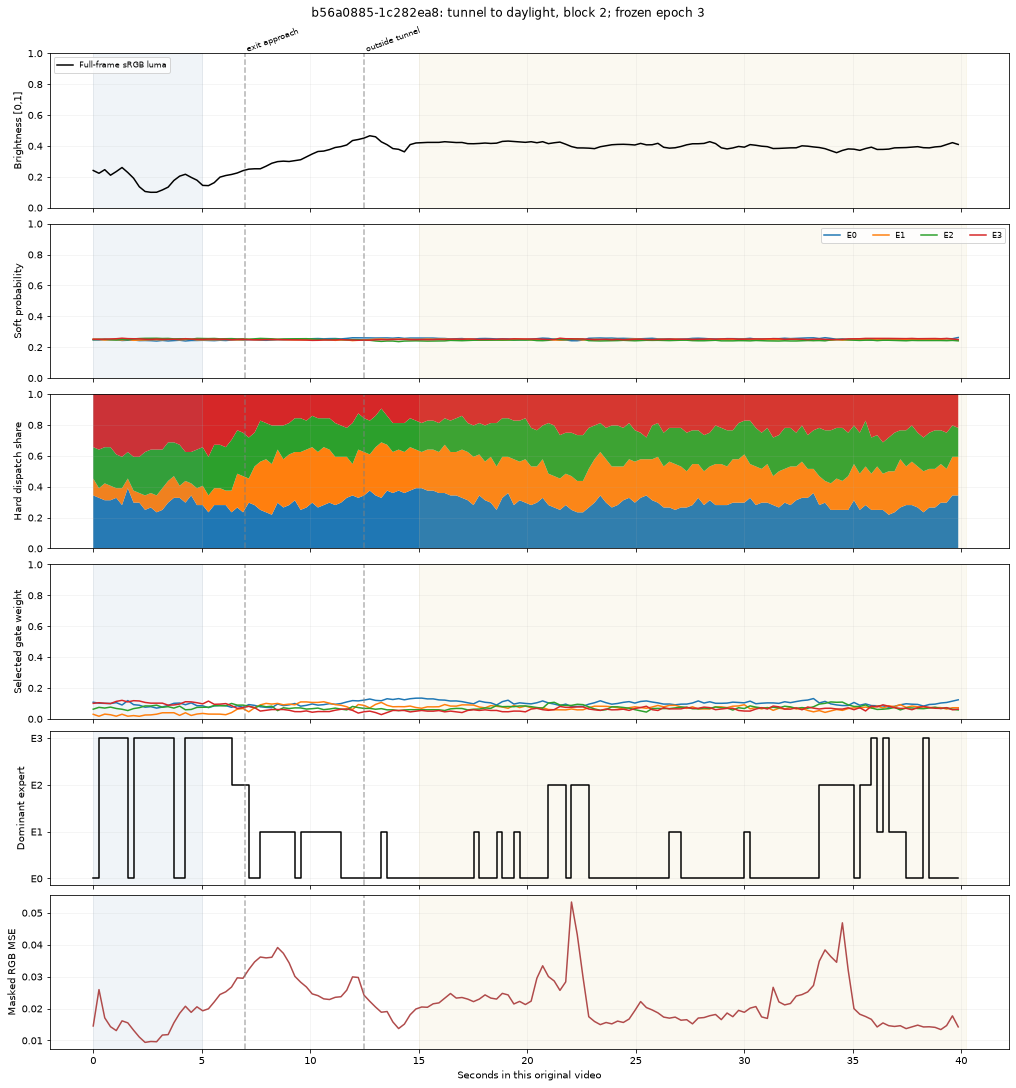

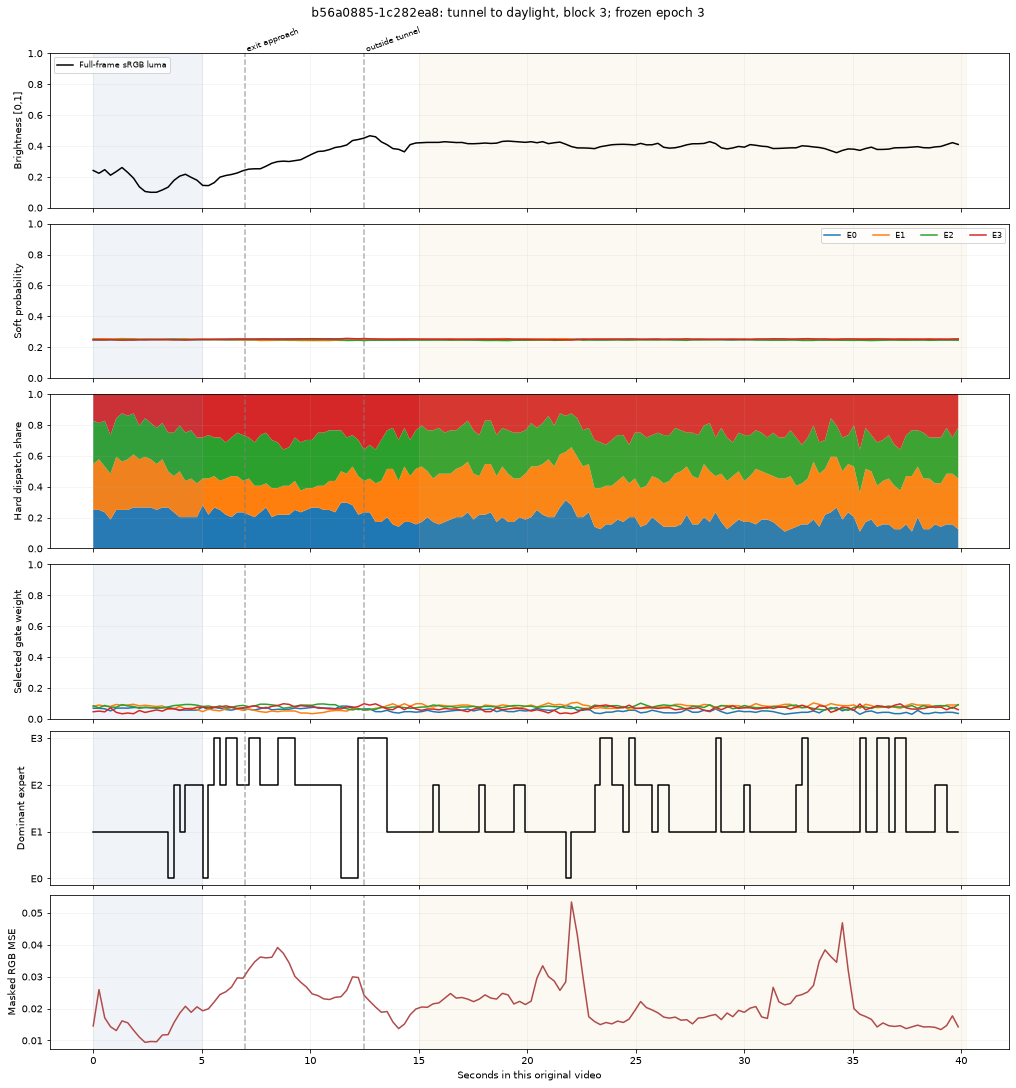

In [9]:
colors = plt.get_cmap("tab10")(np.arange(num_experts) % 10)
for clip_index, spec in enumerate(configured_videos):
    frame = video_results[spec["clip_id"]]
    samples = frame.drop_duplicates("frame_index").sort_values("seconds")
    for block in moe_blocks:
        rows = frame.loc[frame["block"] == block]
        probability = rows.pivot(index="seconds", columns="expert", values="probability").sort_index()
        dispatch = rows.pivot(index="seconds", columns="expert", values="dispatch_share").sort_index()
        gate = rows.pivot(index="seconds", columns="expert", values="selected_weight").sort_index()
        times = probability.index.to_numpy()
        fig, axes = plt.subplots(6, 1, figsize=(14, 15), sharex=True, constrained_layout=True)
        axes[0].plot(samples["seconds"], samples["luma"], color="black", label="Full-frame sRGB luma")
        axes[0].set(ylabel="Brightness [0,1]", ylim=(0, 1))
        axes[0].legend(loc="upper left", fontsize=8)
        for expert in range(num_experts):
            axes[1].plot(times, probability[expert], color=colors[expert], label=f"E{expert}")
            axes[3].plot(times, gate[expert], color=colors[expert])
        axes[2].stackplot(times, *[dispatch[e].to_numpy() for e in range(num_experts)], colors=colors)
        axes[4].step(times, dispatch.to_numpy().argmax(1), where="post", color="black")
        axes[4].set_yticks(range(num_experts), [f"E{e}" for e in range(num_experts)])
        axes[5].plot(samples["seconds"], samples["masked_rgb_mse"], color="#b04b4b")
        axes[1].set(ylabel="Soft probability", ylim=(0, 1))
        axes[2].set(ylabel="Hard dispatch share", ylim=(0, 1))
        axes[3].set(ylabel="Selected gate weight", ylim=(0, 1))
        axes[4].set_ylabel("Dominant expert")
        axes[5].set(xlabel="Seconds in this original video", ylabel="Masked RGB MSE")
        axes[1].legend(ncol=min(num_experts, 4), fontsize=8)
        for ax in axes:
            for phase, color in zip(spec["phases"], ["#7298bd", "#d9c578"], strict=True):
                ax.axvspan(phase["start"], phase["end"], color=color, alpha=0.1)
            for seconds, _label in spec["markers"]:
                ax.axvline(seconds, color="gray", linestyle="--", alpha=0.6)
            ax.grid(alpha=0.15)
        for seconds, label in spec["markers"]:
            axes[0].text(seconds, 1.01, label, fontsize=8, rotation=20)
        fig.suptitle(f"{spec['clip_id']}: tunnel to daylight, block {block}; frozen epoch {checkpoint['epoch']}")
        fig.savefig(run_dir / f"video_{clip_index:02d}_block_{block}_routing.png", dpi=130)
        plt.show()

## How much did each expert's load change?

The table compares the explicitly chosen inside/outside windows. Positive dispatch delta means the expert received a larger share of tokens outside the tunnel. Negative means less. It is valid for the router to keep using the same expert; no switch is forced by the analysis.


,clip_id,block,expert,inside_dispatch_pct,outside_dispatch_pct,dispatch_change_pp
0,b56a0885-1c282ea8,2,0,30.35,29.36,-0.99
1,b56a0885-1c282ea8,2,1,9.87,24.85,14.98
2,b56a0885-1c282ea8,2,2,23.52,23.85,0.33
3,b56a0885-1c282ea8,2,3,36.27,21.94,-14.32
4,b56a0885-1c282ea8,3,0,24.01,17.87,-6.14
5,b56a0885-1c282ea8,3,1,29.36,30.54,1.18
6,b56a0885-1c282ea8,3,2,26.81,26.91,0.10
7,b56a0885-1c282ea8,3,3,19.82,24.68,4.87
8,c2b6d359-e8c54604,2,0,24.51,45.56,21.04
9,c2b6d359-e8c54604,2,1,12.70,15.26,2.56


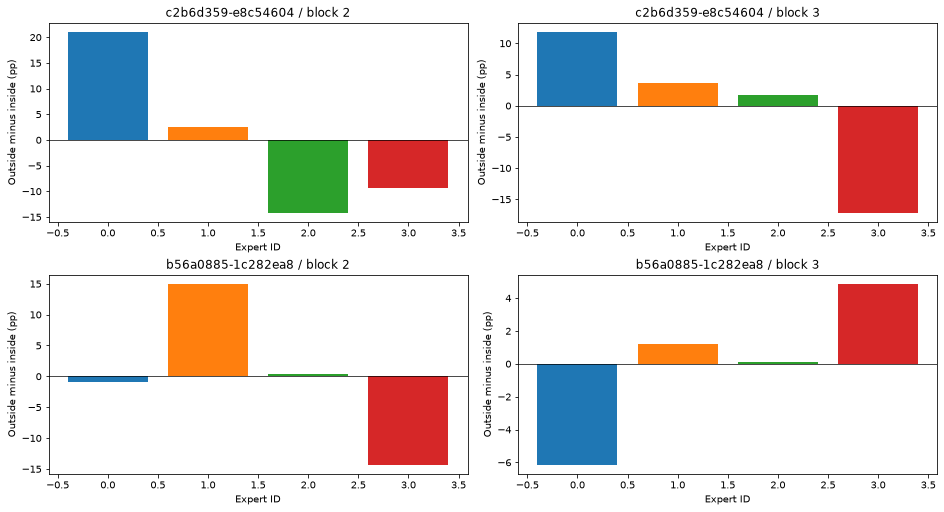

In [10]:
phase_rows, delta_rows = [], []
for spec in configured_videos:
    frame = video_results[spec["clip_id"]]
    for phase in spec["phases"]:
        rows = frame.loc[frame["phase"] == phase["label"]]
        for (block, expert), part in rows.groupby(["block", "expert"]):
            phase_rows.append(
                {
                    "clip_id": spec["clip_id"],
                    "phase": phase["label"],
                    "block": block,
                    "expert": expert,
                    "frames": part["frame_index"].nunique(),
                    "mean_luma": part["luma"].mean(),
                    "mean_probability": part["probability"].mean(),
                    "mean_dispatch_share": part["dispatch_share"].mean(),
                    "mean_selected_weight": part["selected_weight"].mean(),
                    "masked_rgb_mse": part["masked_rgb_mse"].mean(),
                }
            )
phase_summary = pd.DataFrame(phase_rows)
phase_summary.to_csv(run_dir / "phase_summary.csv", index=False)
for keys, rows in phase_summary.groupby(["clip_id", "block", "expert"]):
    parts = rows.set_index("phase")
    delta_rows.append(
        {
            "clip_id": keys[0],
            "block": keys[1],
            "expert": keys[2],
            "inside_dispatch_pct": 100 * parts.loc["inside tunnel", "mean_dispatch_share"],
            "outside_dispatch_pct": 100 * parts.loc["outside tunnel", "mean_dispatch_share"],
            "dispatch_change_pp": 100
            * (parts.loc["outside tunnel", "mean_dispatch_share"] - parts.loc["inside tunnel", "mean_dispatch_share"]),
        }
    )
dispatch_changes = pd.DataFrame(delta_rows)
dispatch_changes.to_csv(run_dir / "dispatch_changes.csv", index=False)
show(dispatch_changes.round(2))
fig, axes = plt.subplots(
    len(configured_videos), len(moe_blocks), figsize=(13, 7), squeeze=False, constrained_layout=True
)
for i, spec in enumerate(configured_videos):
    for j, block in enumerate(moe_blocks):
        rows = dispatch_changes.loc[
            (dispatch_changes["clip_id"] == spec["clip_id"]) & (dispatch_changes["block"] == block)
        ]
        axes[i, j].bar(rows["expert"], rows["dispatch_change_pp"], color=colors)
        axes[i, j].axhline(0, color="black", linewidth=0.7)
        axes[i, j].set(
            title=f"{spec['clip_id']} / block {block}", xlabel="Expert ID", ylabel="Outside minus inside (pp)"
        )
fig.savefig(run_dir / "dispatch_changes.png", dpi=130)
plt.show()

## Check the actual frames

The filmstrip preserves capture order. The reconstruction gallery uses the first clip's inside/transition/outside frames, with only masked patches replaced by decoder predictions. The existing checkpoint remains unchanged throughout evaluation.


[Open original continuous-sequence filmstrip 1](../outputs/bdd-illumination/evaluation/20261026T171217382325Z/video_00_filmstrip.png)

[Open original continuous-sequence filmstrip 2](../outputs/bdd-illumination/evaluation/20261026T171217382325Z/video_01_filmstrip.png)

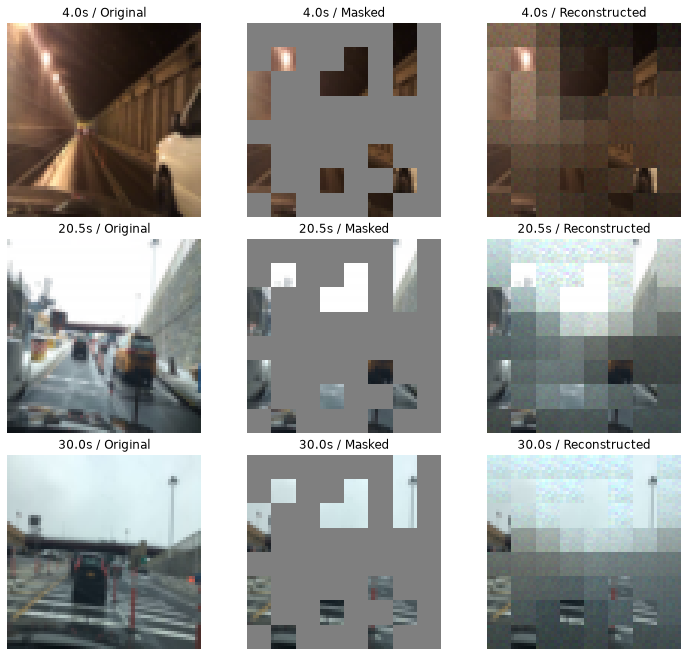

All evaluation artifacts: C:\Users\muham\Documents\Project\cafl4ds\outputs\bdd-illumination\evaluation\20261026T171217382325Z


In [11]:
for clip_index, spec in enumerate(configured_videos):
    frame = video_results[spec["clip_id"]].drop_duplicates("frame_index").sort_values("seconds")
    targets = np.linspace(frame["seconds"].min(), frame["seconds"].max(), 6)
    capture = cv2.VideoCapture(spec["path"])
    fig, axes = plt.subplots(2, 3, figsize=(14, 6), constrained_layout=True)
    try:
        for ax, seconds in zip(axes.flat, targets, strict=True):
            capture.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
            success, bgr = capture.read()
            if not success:
                raise RuntimeError(f"Cannot decode filmstrip at {seconds}.")
            ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
            ax.set_title(f"{seconds:.2f}s")
            ax.axis("off")
    finally:
        capture.release()
    fig.suptitle(spec["clip_id"] + ": original continuous sequence")
    fig.savefig(run_dir / f"video_{clip_index:02d}_filmstrip.png", dpi=120)
    plt.show()

spec = configured_videos[0]
targets = [4.0, 20.5, 30.0]
capture = cv2.VideoCapture(spec["path"])
fig, axes = plt.subplots(3, 3, figsize=(10, 9), constrained_layout=True)
try:
    with torch.no_grad():
        for row, seconds in enumerate(targets):
            capture.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
            success, bgr = capture.read()
            if not success:
                raise RuntimeError("Cannot decode reconstruction frame.")
            images = preprocess_rgb(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))[None].to(device)
            result = method.encoder.forward_with_aux(
                images, mask_ratio=mask_ratio, mask_noise=fixed_mask_noise[:1].to(device)
            )
            prediction = method.decoder(result.tokens, result.ids_restore)
            patches = patchify(images, patch_size)
            mask = result.mask[..., None]
            masked = unpatchify(patches * (1 - mask) + 0.5 * mask, patch_size, 3)
            reconstruction = unpatchify(patches * (1 - mask) + prediction * mask, patch_size, 3)
            for ax, tensor, title in zip(
                axes[row], [images, masked, reconstruction], ["Original", "Masked", "Reconstructed"], strict=True
            ):
                ax.imshow(tensor[0].cpu().clamp(0, 1).permute(1, 2, 0))
                ax.set_title(f"{seconds:.1f}s / {title}")
                ax.axis("off")
finally:
    capture.release()
fig.savefig(run_dir / "reconstructions.png", dpi=130)
plt.show()
print(f"All evaluation artifacts: {run_dir}")

## Spatial expert heatmap videos

**Already rendered from the completed epoch-3 checkpoint:** [Open these videos](../outputs/expert-routing-videos/20261028T171707144378Z/index.html#moe_illumination_transition).


Export synchronized H.264 MP4s with the original image, one heatmap per expert, and a categorical winning-expert patch map for each MoE block. These are **actual spatial router readouts, not gradient-based Grad-CAM or causal feature attributions**. Full unmasked frames are evaluated without router noise or weight updates. CLS is excluded.

**Default: continuous `probability` heatmaps cover every patch for every expert, including experts that were not selected. No top-1 selection mask or threshold is applied to these panels. The final overall expert map remains categorical top-1.**

`selected_weight` is an optional alternative that colors only patches dispatched to that expert; color strength is its full-softmax gate probability (the repository does not renormalize selected weights). `dispatch` displays binary selection, and `probability` shows preferences even for experts that were not selected. The fixed 0–1 color scale is shared across experts and frames. Smooth color interpolation does not add resolution beyond the model's patch grid; selection boundaries remain on the patch grid. Expert IDs have no automatic regime meaning in these unsupervised models.

Exports preserve chronological playback speed at the configured output FPS by holding the preceding source frame between timestamps. Output and source timestamps are saved alongside each MP4. Videos are silent. FFmpeg with `libx264` must be installed and on PATH. The export uses the currently loaded/trained `method`; it does not start training.


In [ ]:
import csv
import os
import shutil
import subprocess
from collections.abc import Callable

from IPython.display import Markdown, Video

heatmap_fps = 10.0
heatmap_mode = "probability"  # Continuous soft probabilities; overall map stays top-1.
heatmap_batch_size = 16
heatmap_panel_width = 256
heatmap_max_seconds = None  # None exports complete clips; e.g. 3.0 is a quick encoding check.
heatmap_output_dir = run_dir / "expert_heatmaps" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

In [ ]:
def routing_video_samples(
    spec: dict[str, Any], source_reader: Callable, fps: float, max_seconds: float | None = None
) -> Iterator[tuple[int, float, float, np.ndarray]]:
    """Resample sequential source frames at constant output FPS using the preceding source frame."""
    reader = source_reader(spec)
    previous, output_time = None, 0.0
    try:
        for current in reader:
            if previous is None:
                previous = current
            while output_time < current[1] - 1e-8:
                if max_seconds is not None and output_time >= max_seconds - 1e-8:
                    return
                yield previous[0], previous[1], output_time, previous[2]
                output_time += 1 / fps
            previous = current
        if previous is None:
            raise ValueError(f"No frames decoded: {spec['path']}")
        while output_time < previous[1] + 1 / previous[3] - 1e-8:
            if max_seconds is not None and output_time >= max_seconds - 1e-8:
                return
            yield previous[0], previous[1], output_time, previous[2]
            output_time += 1 / fps
    finally:
        reader.close()


def expert_routing_mosaic(
    rgb: np.ndarray,
    routing: dict[int, np.ndarray],
    output_seconds: float,
    clip_id: str,
    top_k: int,
    mode: str = "probability",
    panel_width: int = 256,
    alpha: float = 0.65,
    active_experts: dict[int, np.ndarray] | None = None,
) -> np.ndarray:
    """Create original, per-expert heatmaps, and categorical winner panels for every MoE block."""
    if mode not in {"selected_weight", "probability", "dispatch"}:
        raise ValueError("mode must be selected_weight, probability, or dispatch.")
    blocks = sorted(routing)
    experts = next(iter(routing.values())).shape[-1]
    tile_h = panel_width * 9 // 16
    header_h, row_h = 36, tile_h + 56
    width, height = (experts + 2) * panel_width, 56 + len(blocks) * row_h + 40
    width += width % 2
    height += height % 2
    canvas = np.full((height, width, 3), 22, dtype=np.uint8)
    base = cv2.resize(rgb, (panel_width, tile_h), interpolation=cv2.INTER_AREA)
    palette = np.array(
        [
            [76, 120, 168],
            [245, 133, 24],
            [84, 162, 75],
            [228, 87, 86],
            [178, 121, 162],
            [118, 183, 178],
            [237, 201, 72],
            [255, 157, 167],
        ],
        dtype=np.uint8,
    )
    title = f"{clip_id} | {output_seconds:6.2f}s | actual unmasked routing | {mode} (fixed 0-1 scale)"
    cv2.putText(canvas, title, (12, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (240, 240, 240), 1, cv2.LINE_AA)
    cv2.putText(
        canvas,
        "Spatial patch routing, not gradient attribution; expert IDs have no automatic regime meaning",
        (12, 44),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.43,
        (190, 190, 190),
        1,
        cv2.LINE_AA,
    )
    for row, block in enumerate(blocks):
        probabilities = routing[block]
        grid = math.isqrt(len(probabilities))
        if grid * grid != len(probabilities):
            raise ValueError(f"Expected a square spatial patch grid; got {len(probabilities)} tokens.")
        if active_experts is None:
            choices = torch.from_numpy(probabilities).topk(top_k, dim=-1).indices.numpy()
            selected = np.zeros_like(probabilities)
            np.put_along_axis(selected, choices, 1.0, axis=-1)
        else:
            selected = active_experts[block]
        winner = (selected.argmax(-1) if top_k == 1 else probabilities.argmax(-1)).reshape(grid, grid)
        y = 56 + row * row_h

        def panel(column: int, image: np.ndarray, heading: str, footer: str, y_offset: int = y) -> None:
            """Place one synchronized tile with an explicit summary label."""
            x = column * panel_width
            canvas[y_offset + header_h : y_offset + header_h + tile_h, x : x + panel_width] = image
            cv2.putText(
                canvas, heading, (x + 7, y_offset + 16), cv2.FONT_HERSHEY_SIMPLEX, 0.43, (240, 240, 240), 1, cv2.LINE_AA
            )
            cv2.putText(
                canvas,
                footer,
                (x + 7, y_offset + header_h + tile_h + 14),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.36,
                (205, 205, 205),
                1,
                cv2.LINE_AA,
            )

        panel(0, base, f"Original | block {block}", f"{grid} x {grid} model patches; CLS excluded")
        for expert in range(experts):
            soft = probabilities[:, expert].reshape(grid, grid)
            active = selected[:, expert].reshape(grid, grid)
            values = active if mode == "dispatch" else soft
            strength = cv2.resize(values, (panel_width, tile_h), interpolation=cv2.INTER_LINEAR)
            active_pixels = cv2.resize(active, (panel_width, tile_h), interpolation=cv2.INTER_NEAREST)
            colored = cv2.cvtColor(
                cv2.applyColorMap(np.uint8(np.clip(strength, 0, 1) * 255), cv2.COLORMAP_TURBO), cv2.COLOR_BGR2RGB
            )
            mask = np.ones_like(active_pixels) if mode == "probability" else active_pixels
            opacity = (alpha * mask)[..., None]
            overlay = np.uint8(base.astype(float) * (1 - opacity) + colored * opacity)
            share = selected[:, expert].mean() / top_k
            weight = (probabilities[:, expert] * selected[:, expert]).mean()
            panel(
                expert + 1,
                overlay,
                f"Expert {expert} | dispatch {100 * share:5.1f}%",
                f"mean selected gate weight: {weight:.3f}",
            )
        winner_colors = cv2.resize(
            palette[winner % len(palette)], (panel_width, tile_h), interpolation=cv2.INTER_NEAREST
        )
        winner_overlay = cv2.addWeighted(base, 0.45, winner_colors, 0.55, 0)
        panel(
            experts + 1,
            winner_overlay,
            f"Block {block} top-1 expert map",
            "Colors identify experts; not a strength scale",
        )
    legend_y = height - 30
    gradient = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (10, 1))
    bar = cv2.cvtColor(cv2.applyColorMap(gradient, cv2.COLORMAP_TURBO), cv2.COLOR_BGR2RGB)
    canvas[legend_y : legend_y + 10, 12:268] = bar
    cv2.putText(
        canvas,
        "0.0          0.25           0.5           0.75          1.0",
        (12, height - 6),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.30,
        (225, 225, 225),
        1,
        cv2.LINE_AA,
    )
    for expert in range(experts):
        x = 300 + expert * 115
        cv2.rectangle(
            canvas, (x, legend_y), (x + 14, legend_y + 14), tuple(int(v) for v in palette[expert % len(palette)]), -1
        )
        cv2.putText(
            canvas,
            f"Expert {expert}",
            (x + 20, legend_y + 12),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (225, 225, 225),
            1,
            cv2.LINE_AA,
        )
    return canvas


@torch.no_grad()
def export_expert_routing_video(  # noqa: C901 - keep streaming decode/encode cleanup in one scope.
    model: torch.nn.Module,
    spec: dict[str, Any],
    output_path: str | Path,
    preprocess: Callable[[np.ndarray], torch.Tensor],
    source_reader: Callable,
    fps: float = 10.0,
    batch_size: int = 16,
    mode: str = "probability",
    panel_width: int = 256,
    max_seconds: float | None = None,
) -> dict[str, Any]:
    """Export real-time-speed H.264 routing overlays with frozen weights and timestamp provenance."""
    if not math.isfinite(fps) or fps <= 0 or batch_size < 1:
        raise ValueError("Use positive output FPS and batch size.")
    executable = shutil.which("ffmpeg")
    if executable is None:
        raise FileNotFoundError(
            "FFmpeg is required for browser-compatible H.264 MP4 output; install it and add it to PATH."
        )
    target = Path(output_path)
    if target.exists():
        raise FileExistsError(f"Refusing to overwrite video: {target}")
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(".partial.mp4")
    log_path = target.with_suffix(".ffmpeg.log")
    csv_path = target.with_suffix(".timestamps.csv")
    device = next(model.parameters()).device
    encoder = model.encoder if hasattr(model, "encoder") else model
    blocks = tuple(encoder.moe_blocks)
    top_k = encoder.blocks[blocks[0]].mlp.top_k
    modes = {module: module.training for module in model.modules()}
    model.eval()
    process, count, last_time, shape = None, 0, 0.0, None
    reader = routing_video_samples(spec, source_reader, fps, max_seconds)
    with log_path.open("w", encoding="utf-8") as log, csv_path.open("w", newline="", encoding="utf-8") as csv_file:
        table = csv.writer(csv_file)
        table.writerow(["output_frame", "output_seconds", "source_frame", "source_seconds"])
        try:
            exhausted = False
            while not exhausted:
                batch = []
                for _ in range(batch_size):
                    item = next(reader, None)
                    if item is None:
                        exhausted = True
                        break
                    batch.append(item)
                if not batch:
                    break
                images = torch.stack([preprocess(item[3]) for item in batch]).to(device)
                clean = {block: probability[:, 1:, :] for block, probability in encoder.routing(images).items()}
                routing = {block: probability.cpu().numpy() for block, probability in clean.items()}
                active = {
                    block: torch.nn.functional.one_hot(probability.topk(top_k, dim=-1).indices, probability.shape[-1])
                    .sum(-2)
                    .cpu()
                    .numpy()
                    for block, probability in clean.items()
                }
                for index, (source_index, source_seconds, output_seconds, rgb) in enumerate(batch):
                    frame = expert_routing_mosaic(
                        rgb,
                        {block: values[index] for block, values in routing.items()},
                        output_seconds,
                        spec["clip_id"],
                        top_k,
                        mode,
                        panel_width,
                        active_experts={block: values[index] for block, values in active.items()},
                    )
                    if process is None:
                        shape = frame.shape
                        command = [
                            executable,
                            "-hide_banner",
                            "-loglevel",
                            "error",
                            "-n",
                            "-f",
                            "rawvideo",
                            "-pixel_format",
                            "rgb24",
                            "-video_size",
                            f"{shape[1]}x{shape[0]}",
                            "-framerate",
                            str(fps),
                            "-i",
                            "pipe:0",
                            "-an",
                            "-c:v",
                            "libx264",
                            "-preset",
                            "veryfast",
                            "-crf",
                            "22",
                            "-pix_fmt",
                            "yuv420p",
                            "-threads",
                            "2",
                            "-movflags",
                            "+faststart",
                            str(temporary),
                        ]
                        process = subprocess.Popen(command, stdin=subprocess.PIPE, stderr=log)  # noqa: S603 - fixed argv, no shell.
                    process.stdin.write(frame.tobytes())
                    table.writerow([count, f"{output_seconds:.6f}", source_index, f"{source_seconds:.6f}"])
                    count += 1
                    last_time = output_seconds
            if process is None:
                raise ValueError("No video frames were produced.")
            process.stdin.close()
            if process.wait(timeout=120) != 0:
                raise RuntimeError(f"FFmpeg failed; inspect {log_path}")
            temporary.replace(target)
        finally:
            reader.close()
            if process is not None and process.poll() is None:
                process.terminate()
                process.wait(timeout=15)
            for module, training in modes.items():
                module.training = training
    report = {
        "clip_id": spec["clip_id"],
        "path": str(target),
        "source": spec["path"],
        "frames": count,
        "fps": fps,
        "duration_seconds": count / fps,
        "last_output_seconds": last_time,
        "width": shape[1],
        "height": shape[0],
        "map_mode": mode,
        "blocks": list(blocks),
        "map_scale": [0, 1],
        "silent": True,
        "timestamps": str(csv_path),
        "note": "Actual unmasked routing; CLS excluded; smooth colors over model patches; not gradient attribution.",
    }
    target.with_suffix(".json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    return report


def routing_overlay_source(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Reuse the notebook's original chronological video/frame readers without plot-time subsampling."""
    return directory_video_frames(spec) if Path(spec["path"]).is_dir() else decoded_video_frames(spec)

In [ ]:
heatmap_reports = []
for spec in configured_videos:
    safe_clip_id = re.sub(r"[^A-Za-z0-9_.-]", "_", spec["clip_id"])
    target = heatmap_output_dir / f"{safe_clip_id}_{heatmap_mode}.mp4"
    print(f"Rendering {spec['clip_id']} at {heatmap_fps:g} FPS...")
    report = export_expert_routing_video(
        method,
        spec,
        target,
        preprocess_rgb,
        routing_overlay_source,
        fps=heatmap_fps,
        batch_size=heatmap_batch_size,
        mode=heatmap_mode,
        panel_width=heatmap_panel_width,
        max_seconds=heatmap_max_seconds,
    )
    heatmap_reports.append(report)
if heatmap_reports:
    (heatmap_output_dir / "manifest.json").write_text(dumps_valid(heatmap_reports), encoding="utf-8")
    show(pd.DataFrame(heatmap_reports)[["clip_id", "fps", "duration_seconds", "frames", "map_mode", "path"]])
    for report in heatmap_reports:
        relative = Path(os.path.relpath(report["path"], repo_root / "notebooks")).as_posix()
        show(Markdown(f"[Open expert heatmap video: {report['clip_id']}]({relative})"))
    # Linked media avoids embedding large MP4 byte strings in the notebook file.
    first_video = Path(os.path.relpath(heatmap_reports[0]["path"], repo_root / "notebooks")).as_posix()
    show(Video(url=first_video, embed=False, width=1000))
else:
    print("No video clips configured; add actual video paths before exporting heatmaps.")